## **BERN02 - Challenge Project**
### **Project Title:** Comparative Evaluation of Regression Models for Predicting Parkinson’s Disease Severity
### **Author:** Yang Shann Wen
---

#### **Introduction:**

**Parkinson's disease (PD)** is a progressive neurodegenerative disorder that causes a person to experience movement-related symptoms, such as tremor, slowness of movement and balance problems, as well as non-motor symptoms like hallucinations, depression and loss of sense of smell. This project focuses on **evaluating the predictive performance of different regression models for estimating Parkinson's disease severity using demographic and voice measurement features.** Linear regression and nonlinear models are compared using test-set performance metrics.

<br>

The project is structured into several sections:
1. Data Loading
2. Data Cleaning and Preprocessing
3. Exploratory Data Analysis
4. Model Development
5. Model Evaluation and Comparison
6. Conclusion

---
#### **1. Data Loading**
Firstly, we import libraries used throughout the project and load the dataset.

This project uses the **Oxford Parkinson's Disease Telemonitoring Dataset**, obtained from the UCI Machine Learning Repository. The dataset contains 5,875 voice recordings collected from 42 individuals with early-stage Parkinson's disease during a six-month telemonitoring study. The recordings were collected in participants' homes and include demographic information, biomedical voice measurements, and clinical symptom severity scores.

In this project, each row represents an individual voice recording rather than a unique patient. The dataset includes **16 biomedical voice measures, along with variables such as age, sex, recording time, and the motor and total Unified Parkinson's Disease Rating Scale (UPDRS) scores**.

The objective of this project is to compare the predictive performance of different regression models in **estimating `total_UPDRS`** using demographic and acoustic features. The **`total_UPDRS` variable is defined as the target**, while `subject#`, `motor_UPDRS`, and `test_time` are excluded from the predictors. The subject identifier is excluded because it is not a meaningful measurement of symptom severity; `motor_UPDRS` is excluded because it represents a component of the total score and could introduce target leakage; and `test_time` is excluded because this analysis focuses on predictions based on demographic and acoustic features rather than elapsed time. Hence, we will have **18 predictors**, with the target `total_UPDRS`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor

# Standardise plot styling and colors
MAIN_COLOR = "#90CAF9"
ACCENT_COLOR = "#C44E52"

sns.set_theme(style="ticks", palette="deep")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[MAIN_COLOR, ACCENT_COLOR, "#8172B2"]),
    "axes.grid": True,                # Enable gridlines globally
    "axes.grid.axis": "y",            # Only horizontal (y-axis) gridlines
    "grid.color": "0.85",             # Gridline color
    "grid.linestyle": "--",           # Gridline style
    "grid.linewidth": 0.6,            # Gridline weight
    "grid.alpha": 0.8,                # Semi-transparent gridline
    "axes.axisbelow": True,           # Always draw gridlines behind bars/boxes
    "axes.edgecolor": "0.15",         # Color of axis border
    "axes.linewidth": 0.8,            # Thickness of axis border
    "patch.edgecolor": "black",       # Border color of bars, boxplots,
    "patch.linewidth": 0.5,           # Thickness of border line
    "patch.force_edgecolor": True,
    "figure.titlesize": 14,           # Font size for main figure titles (plt.suptitle)
    "axes.titlesize": 12,             # Font size for individual subplot titles (plt.title / ax.set_title)
    "axes.labelsize": 10,             # Font size for axis labels
    "figure.titleweight": "bold",     # Bold main figure titles (plt.suptitle)
    "axes.titleweight": "bold",       # Bold individual plot titles (plt.title / ax.set_title)
})

In [2]:
# Load dataset
df = pd.read_csv('data/parkinsons_updrs.data')

In [3]:
# Check shape of dataset
print("Dataset dimensions:", df.shape)

Dataset dimensions: (5875, 22)


In [4]:
# Have a look at the dataset
df.head()

,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [5]:
# Inspect data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR            5875 non-null   float64
 18  HNR            5875

In [6]:
# Remove columns that are excluded from the project: subject#, motor_UPDRS, test_time
exclude_cols = ["subject#", "test_time", "motor_UPDRS"]
df_model = df.drop(columns=exclude_cols)

# Check the shape of the new dataset
print("Dataset dimensions:", df_model.shape)

Dataset dimensions: (5875, 19)


In [7]:
# Have a look at the new dataset
df_model.head()

,age,sex,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,72,0,34.398,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,72,0,34.894,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,72,0,35.389,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,72,0,35.810,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,72,0,36.375,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [8]:
# Inspect the data statistics
df_model.describe()

,age,sex,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
count,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000
mean,64.804936,0.317787,29.018942,0.006154,0.000044,0.002987,0.003277,0.008962,0.034035,0.310960,0.017156,0.020144,0.027481,0.051467,0.032120,21.679495,0.541473,0.653240,0.219589
std,8.821524,0.465656,10.700283,0.005624,0.000036,0.003124,0.003732,0.009371,0.025835,0.230254,0.013237,0.016664,0.019986,0.039711,0.059692,4.291096,0.100986,0.070902,0.091498
min,36.000000,0.000000,7.000000,0.000830,0.000002,0.000330,0.000430,0.000980,0.003060,0.026000,0.001610,0.001940,0.002490,0.004840,0.000286,1.659000,0.151020,0.514040,0.021983
25%,58.000000,0.000000,21.371000,0.003580,0.000022,0.001580,0.001820,0.004730,0.019120,0.175000,0.009280,0.010790,0.015665,0.027830,0.010955,19.406000,0.469785,0.596180,0.156340
50%,65.000000,0.000000,27.576000,0.004900,0.000035,0.002250,0.002490,0.006750,0.027510,0.253000,0.013700,0.015940,0.022710,0.041110,0.018448,21.920000,0.542250,0.643600,0.205500
75%,72.000000,1.000000,36.399000,0.006800,0.000053,0.003290,0.003460,0.009870,0.039750,0.365000,0.020575,0.023755,0.032715,0.061735,0.031463,24.444000,0.614045,0.711335,0.264490
max,85.000000,1.000000,54.992000,0.099990,0.000446,0.057540,0.069560,0.172630,0.268630,2.107000,0.162670,0.167020,0.275460,0.488020,0.748260,37.875000,0.966080,0.865600,0.731730


---
#### **2. Data Cleaning and Preprocessing**
After loading the dataset, we check for missing values and duplicate records to assess data quality. We also examine the data for implausible values, such as negative ages or unusually large measurements, to identify potential outliers or data-entry errors.

After completing the data checks, we define the predictor variables (X) and the target variable (y). The target, `total_UPDRS`, represents the overall severity score to be predicted, while the selected demographic and acoustic features serve as predictors.

In [9]:
# Drop null values and duplicates
df_cleaned = df_model.dropna()
df_cleaned = df_cleaned.drop_duplicates()

# Check the shape of cleaned dataset
print(f"Cleaned dataset shape: {df_cleaned.shape}")

Cleaned dataset shape: (5875, 19)


In [10]:
# Target
target = "total_UPDRS"
y = df_cleaned[target]

# Predictors
X = df_cleaned.drop(columns=[target])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget (y):", target)
print("\nPredictors (X):")
print(X.columns.tolist())

X shape: (5875, 18)
y shape: (5875,)

Target (y): total_UPDRS

Predictors (X):
['age', 'sex', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


---
#### **3. Exploratory Data Analysis**
In this section, exploratory data analysis (EDA) is conducted to understand the distributions of the target variable and predictors, identify potential patterns and unusual observations, and examine relationships among variables before developing regression models.

**3.1 Distribution of the Target Variable**

The distribution of `total_UPDRS` is examined using a histogram and a boxplot.
- **Histogram**: To understand the overall distribution of the target variable, including its range, concentration of observations, skewness, and possible multiple peaks.
- **Boxplot:** To summarise the median and spread of the target variable and identify potential outliers.

Understanding the target distribution provides context for interpreting model predictions and evaluating whether prediction errors may vary across different severity levels.

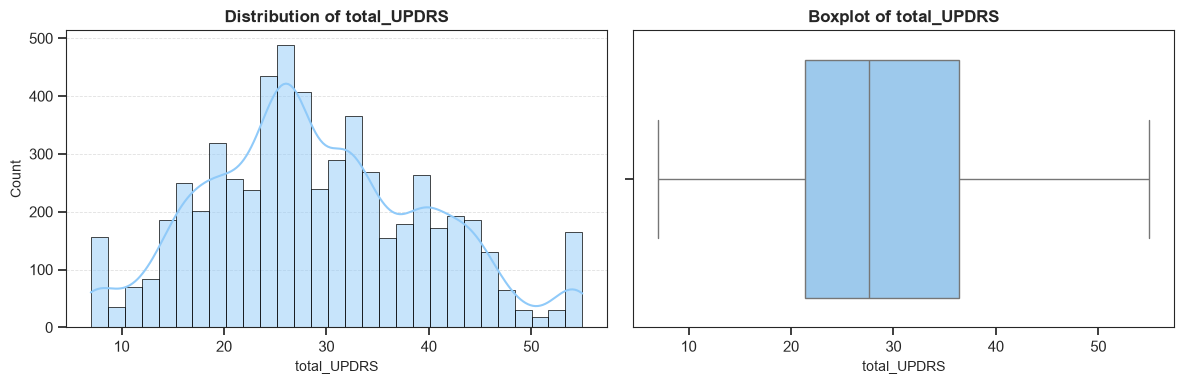

In [11]:
# Distribution of the target variable
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
sns.histplot(y, kde=True, ax=axes[0],color=MAIN_COLOR)
axes[0].set_title("Distribution of total_UPDRS")

# Boxplot
sns.boxplot(x=y, ax=axes[1], color=MAIN_COLOR)
axes[1].set_title("Boxplot of total_UPDRS")

plt.tight_layout()
plt.show()

**Observations from the Plots:**
- **Range & Central Tendency:** `total_UPDRS` ranges from roughly 7 to 55, with a median of approximately 28 and the middle 50% of observations ($Q_1$ to $Q_3$) falling between 21 and 36.
- **Shape:** The distribution peaks around 25–27 and exhibits mild right skewness. The KDE curve highlights smaller secondary bumps and boundary clusters at ~7 and ~55. This happens as the dataset contains repeated measurements from the same 42 patients over time, so each patient's recordings cluster around their own typical severity score.
- **Outliers & Modelling Impact:** The boxplot shows no extreme outliers beyond the whiskers. The target variable is well-behaved and does not require a log transformation, though predictive models may show higher variance in the sparser regions near the upper and lower tails (10–13 and 47–53) compared to the dense central region (15–45).

**3.2 Distribution of Continuous Predictors**

Histograms and boxplots are used to examine the distributions of the continuous predictor variables, including demographic and acoustic features.
- **Histograms:** To examine the shape of each predictor's distribution, such as whether it is approximately symmetric, skewed, or concentrated within a particular range.
- **Boxplots:** To compare the spread of observations and identify potential outliers or unusually extreme values.

These plots help identify characteristics that may be relevant to preprocessing and model development. Potential outliers are not automatically removed, as they may represent genuine biological variation or meaningful measurements rather than errors.

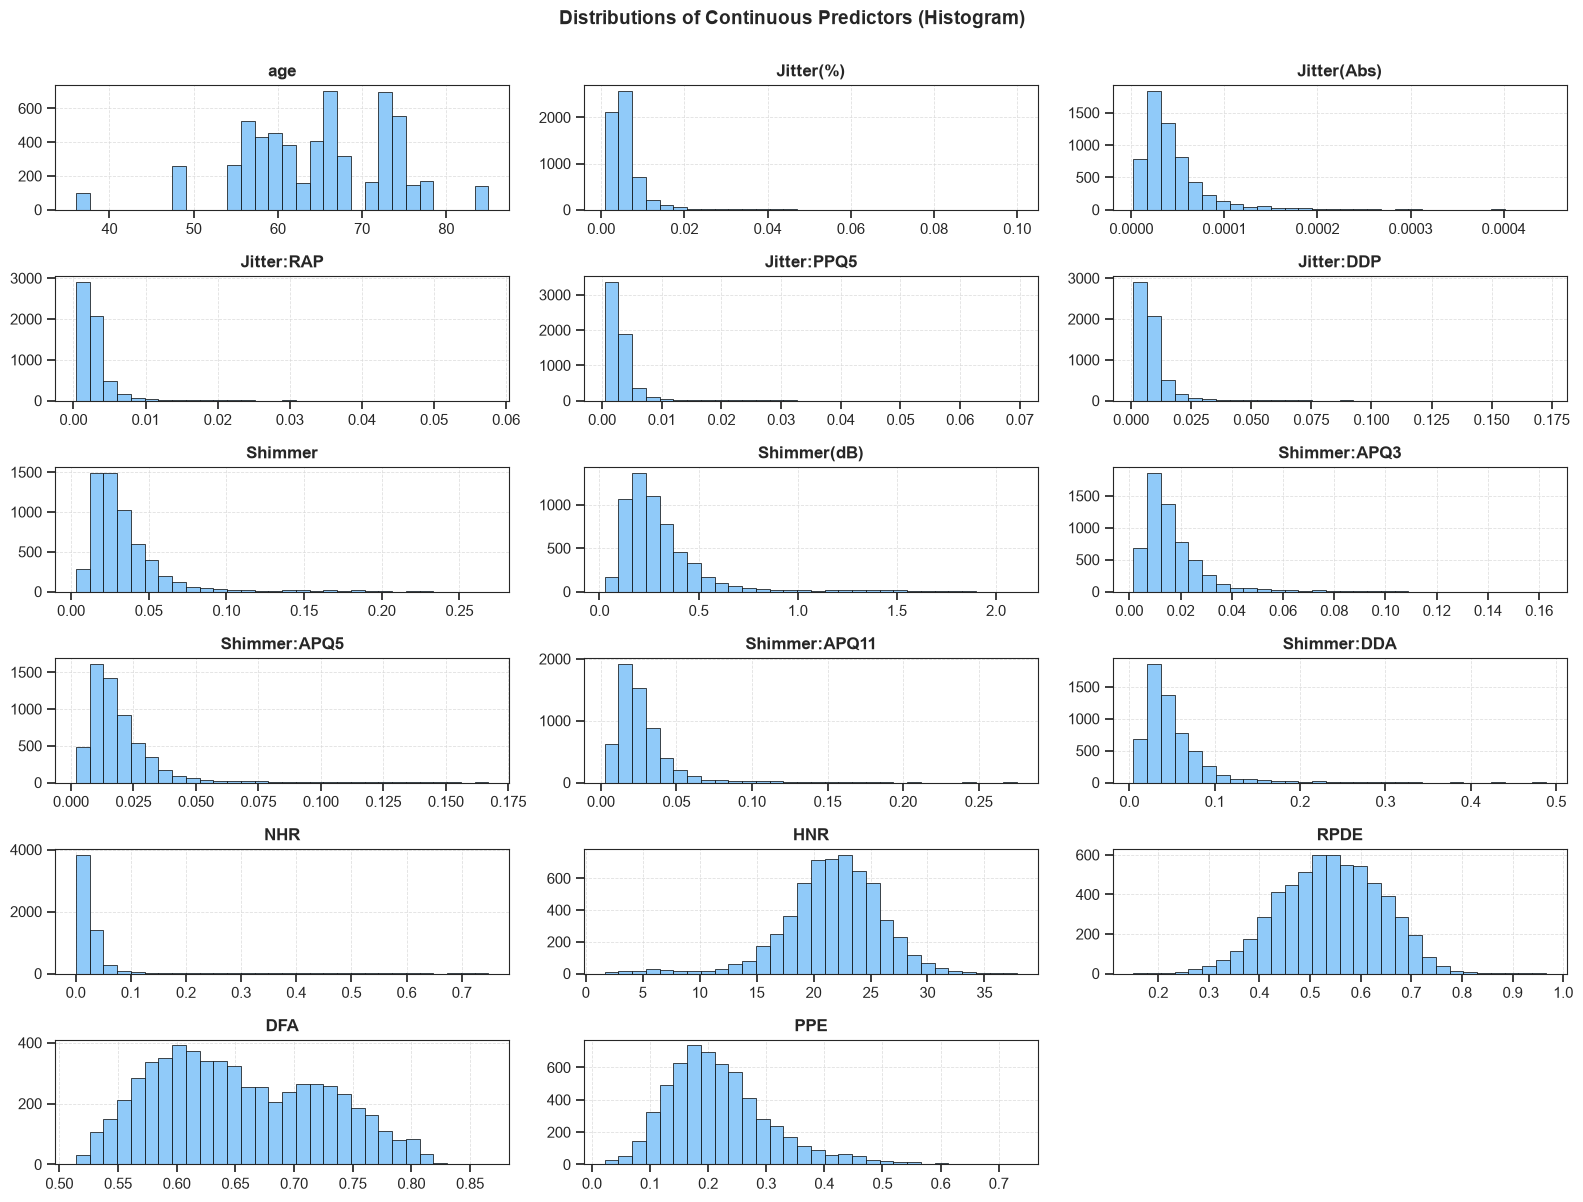

In [12]:
# Distribution of continuous predictors (histograms)
continuous_cols = X.select_dtypes(include="number").columns.drop(
    "sex", errors="ignore"
)

X[continuous_cols].hist(
    figsize=(16, 12),
    bins=30,
    layout=(6, 3),
    color=MAIN_COLOR,
)

plt.suptitle("Distributions of Continuous Predictors (Histogram)", y=1)
plt.tight_layout()
plt.show()

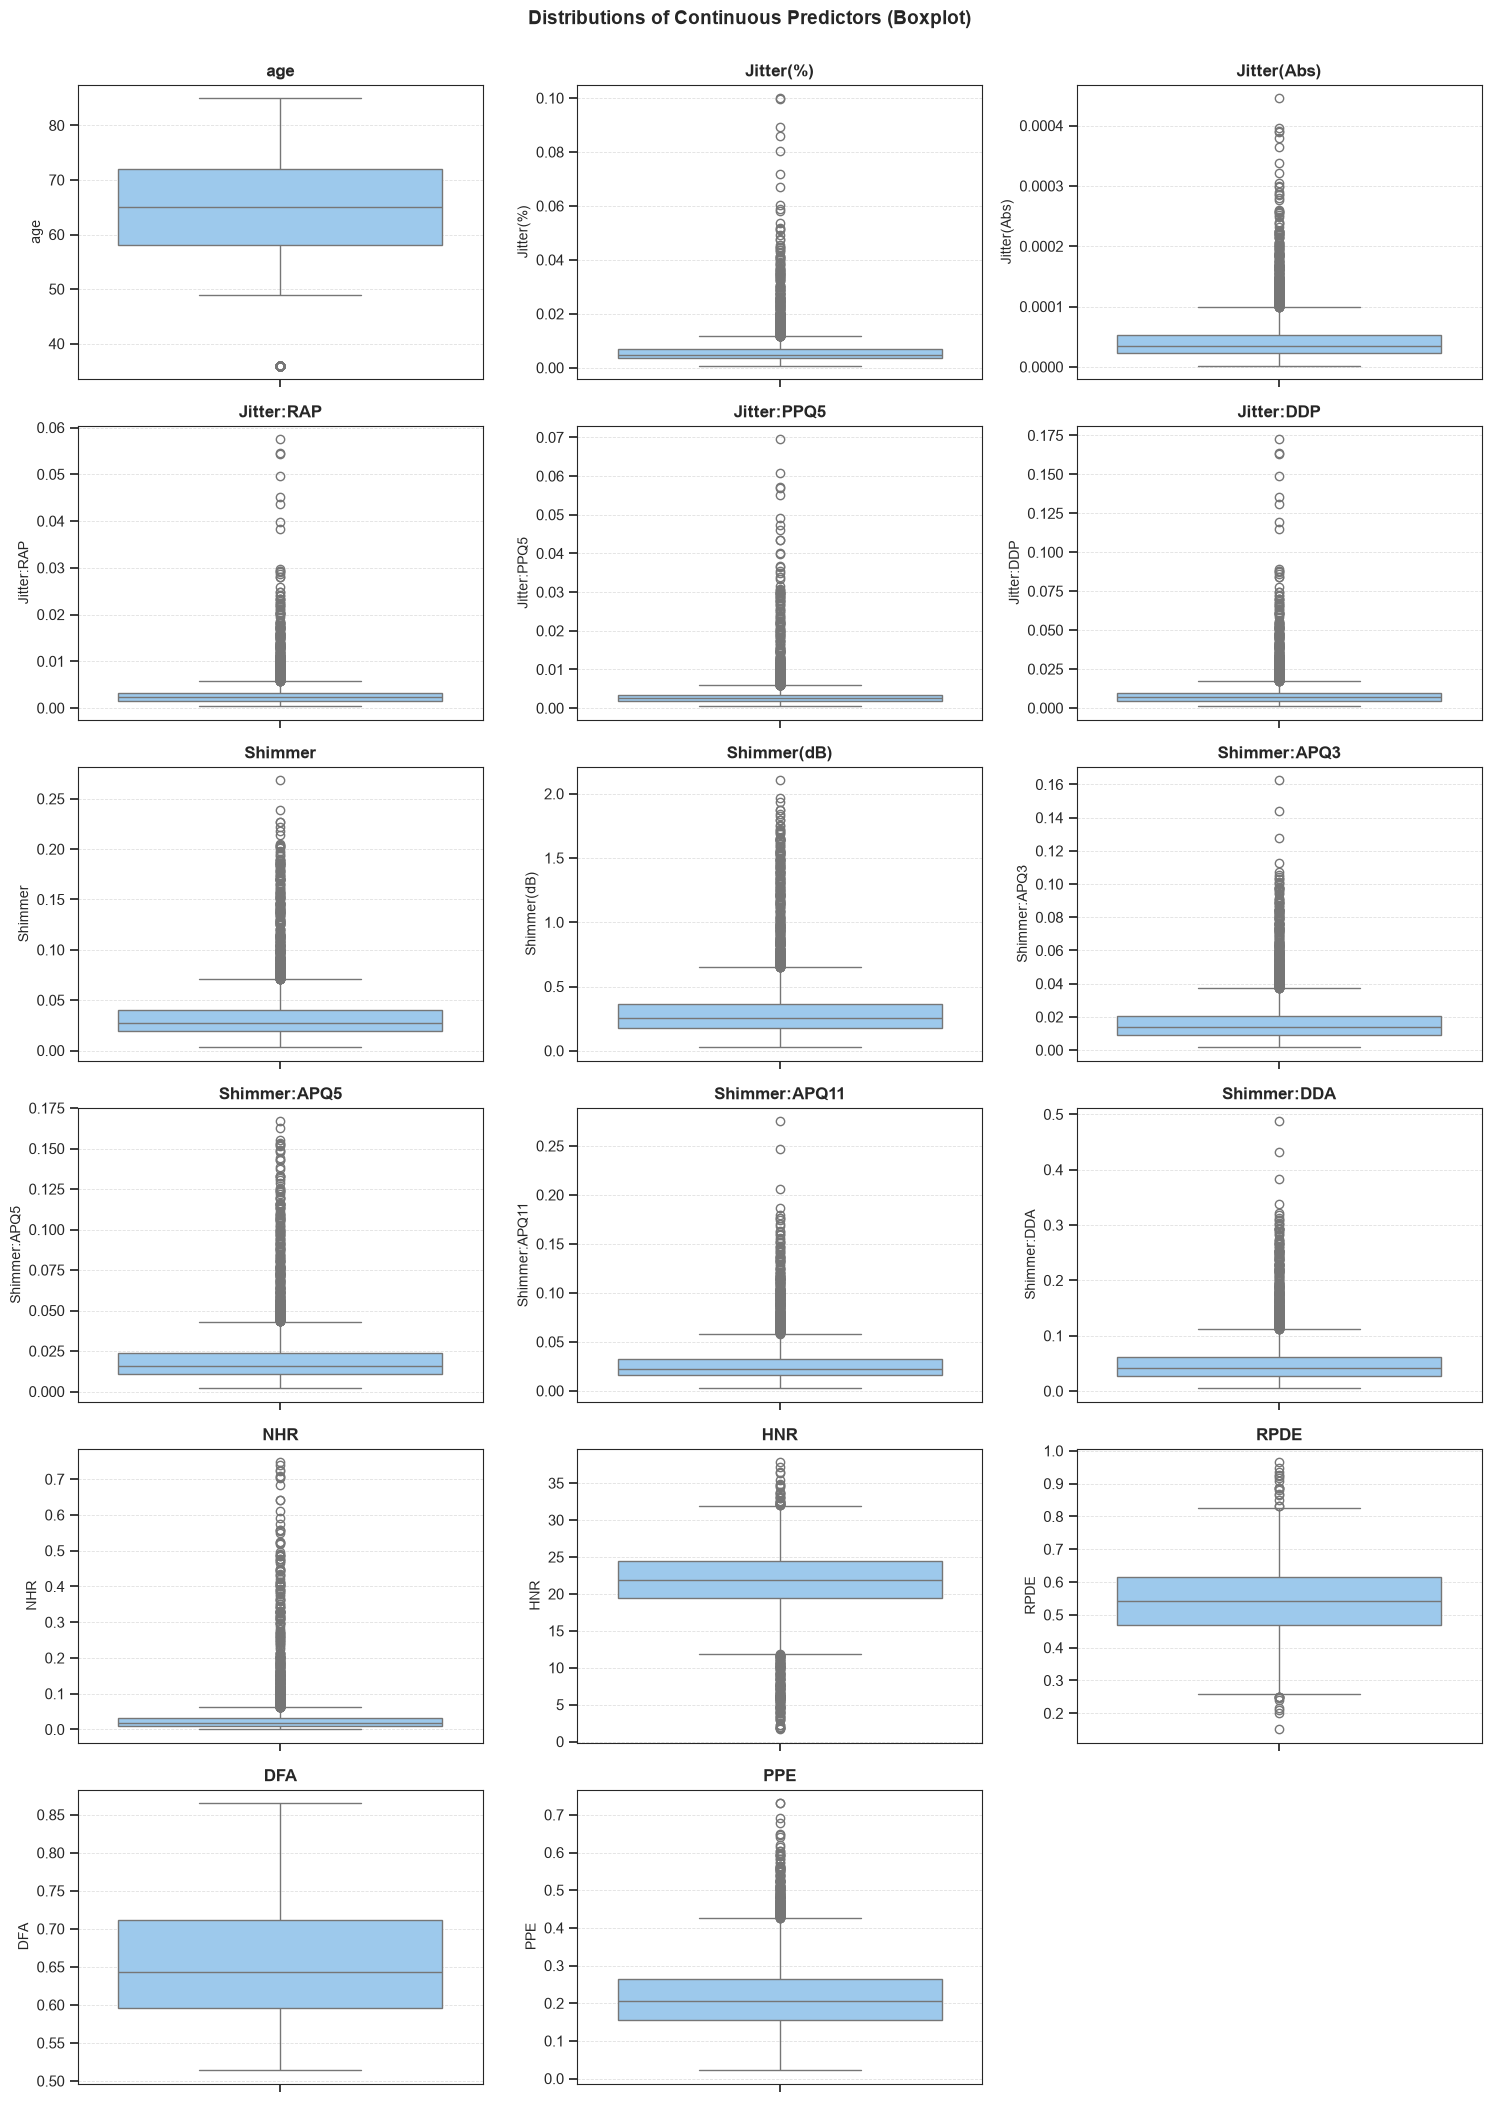

In [13]:
# Distribution of continuous predictors (boxplots)
n_cols = 3
n_rows = (len(continuous_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, n_rows * 3.5)
)

axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.boxplot(data=X, y=col, ax=axes[i], color=MAIN_COLOR)
    axes[i].set_title(f"{col}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel(col)

# Hide unused subplot spaces
for j in range(len(continuous_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distributions of Continuous Predictors (Boxplot)", y=1)
plt.tight_layout()
plt.show()

**Observations from the Plots:**

- **Demographic Predictor (`age`):**
  - The histogram shows a discrete, blocky distribution spanning roughly 36 to 85 years, with most recordings concentrated between 55 and 78 years. This spiky pattern reflects repeated measurements from a fixed cohort of patients, where each patient's age remains constant.
  - The boxplot shows a median age of 65 (IQR from ~58 to 72), with only a single outlier around age 36 (representing the youngest patient in the cohort).

  <br>

- **Heavily Right-Skewed Features (`Jitter`, `Shimmer`, and `NHR`):**
  - All five `Jitter` measures (`Jitter(%)`, `Jitter(Abs)`, `Jitter:RAP`, `Jitter:PPQ5`, `Jitter:DDP`), all six `Shimmer` measures (`Shimmer`, `Shimmer(dB)`, `Shimmer:APQ3`, `Shimmer:APQ5`, `Shimmer:APQ11`, `Shimmer:DDA`), and `NHR` exhibit extreme right skewness.
  - In the histograms, the vast majority of observations are tightly compressed near zero, with long right tails extending toward higher values.
  - Correspondingly, the boxplots display very narrow interquartile boxes near the bottom of each axis and dense vertical trails of upper outliers. Rather than data entry errors, these extreme values represent severe vocal instability, tremor, or breathiness in Parkinson's patients. Therefore, these outliers are retained in the dataset.

  <br>

- **Approximately Symmetric & Moderately Skewed Nonlinear Features (`HNR`, `RPDE`, `DFA`, `PPE`):**
  - **`HNR`:** Centered around a median of ~22 with a roughly bell-shaped distribution, though slightly left-skewed with outliers at both tails (especially below 12, corresponding to noisy recordings).
  - **`RPDE`:** Follows a nearly symmetric, bell-shaped distribution centered around ~0.54, with a modest number of outliers at both the upper (>0.83) and lower (<0.26) ends.
  - **`DFA`:** Spans from ~0.50 to 0.86 with a bimodal (two-peaked) histogram (peaks near ~0.60 and ~0.72) and is the only acoustic predictor with zero outliers in its boxplot.
  - **`PPE`:** Moderately right-skewed, peaking around ~0.18–0.20 (median ~0.20) with upper outliers extending above ~0.43.

  <br>

**Implications for Model Development:**

**1. Standardisation is Essential:** The predictors operate on different scales. For example, `Jitter(Abs)` is measured on the order of $10^{-5}$, whereas `HNR` and `age` reach values of 35–85. Hence, it is important to standardise all continuous predictors (zero mean, unit variance) before fitting regression models.

**2. Handling Skewness & Outliers:** While tree-based models are naturally robust to the heavy skewness and extreme values in `Jitter`, `Shimmer`, and `NHR`, linear models may be sensitive to high-leverage points in the upper tails.

**3.3 Relationships Between Predictors and `total_UPDRS`**

**Scatterplots** and **boxplots** are used to explore the relationships between the predictors and `total_UPDRS` (scatterplots are shown for a representative subset of numerical predictors, alongside a boxplot for the binary `sex` variable).

- **Scatterplots:** Help assess the direction, strength, and form of the relationships for continuous predictors, including whether they appear approximately linear or exhibit nonlinear patterns, clusters, or changes in variability.
- **Boxplot (`sex` vs `total_UPDRS`):** Compares the distribution, median, and interquartile spread of `total_UPDRS` across male (`0`) and female (`1`) patients.

This analysis is particularly relevant when comparing linear regression models with more flexible nonlinear models. However, visual patterns alone are not sufficient to determine which model will perform best; predictive performance must be evaluated using appropriate validation methods.

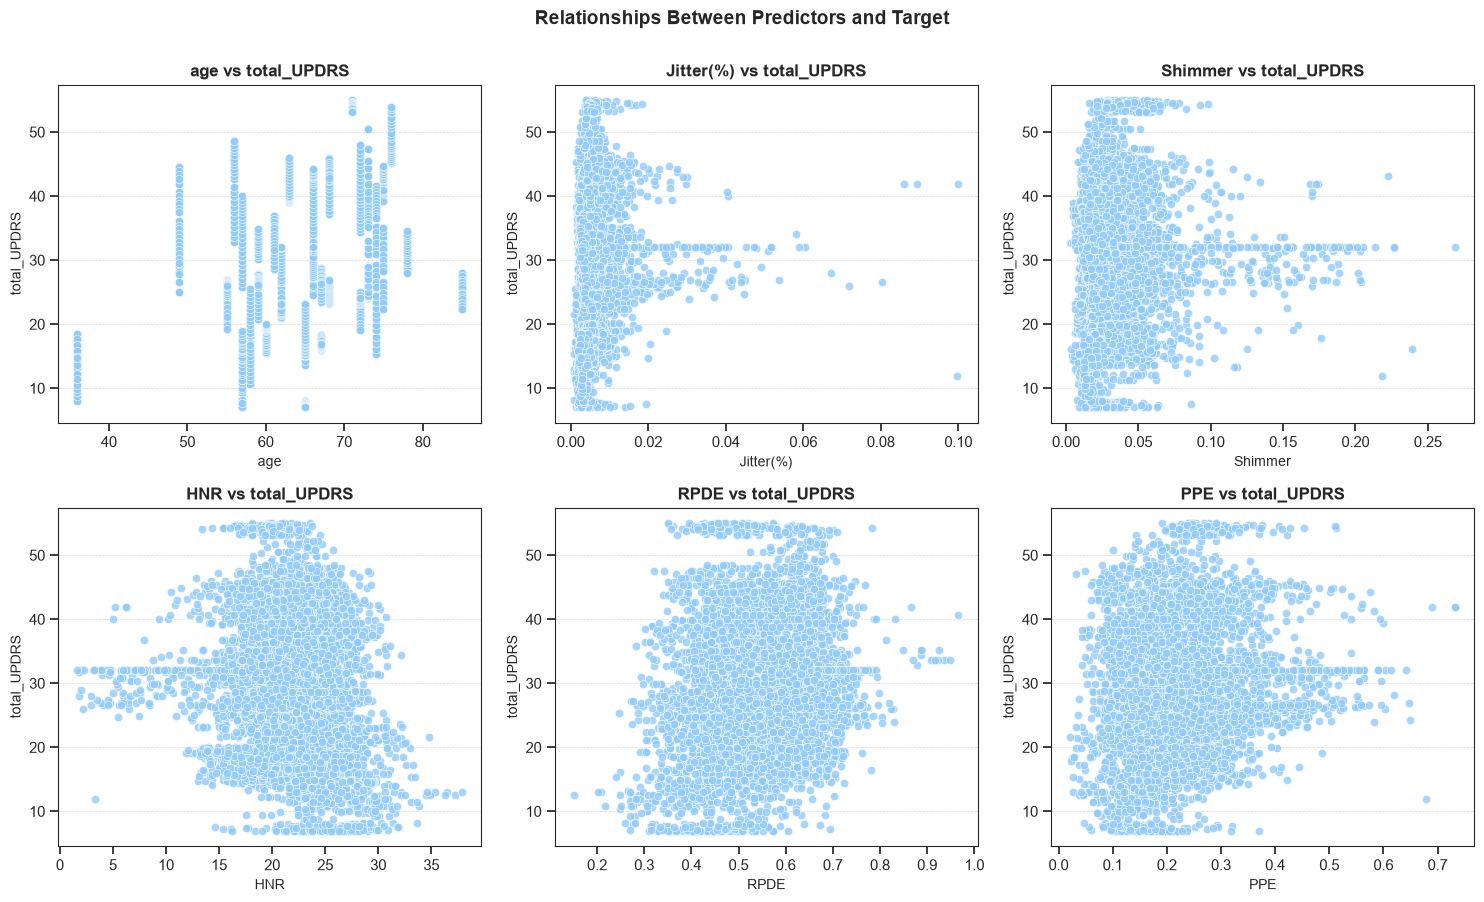

In [14]:
# Relationships between selected predictors and 'total_UPDRS'
selected_features = [
    "age", "Jitter(%)", "Shimmer",
    "HNR", "RPDE", "PPE"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, selected_features):
    sns.scatterplot(
        data=df, x=feature, y="total_UPDRS",
        alpha=0.8, ax=ax,
        color=MAIN_COLOR
    )
    ax.set_title(f"{feature} vs total_UPDRS")

plt.suptitle("Relationships Between Predictors and Target", y=1)
plt.tight_layout()
plt.show()

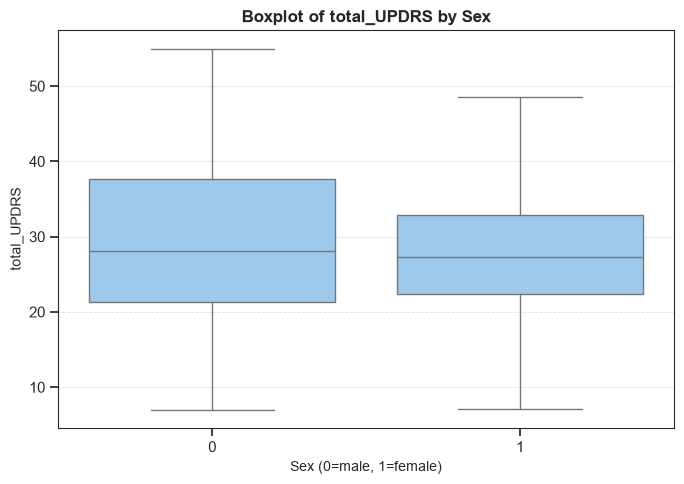

In [15]:
# Relationship between 'sex' and 'total_UPDRS'
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="sex", y="total_UPDRS", color=MAIN_COLOR)

plt.title("Boxplot of total_UPDRS by Sex")
plt.xlabel("Sex (0=male, 1=female)")
plt.ylabel("total_UPDRS")
plt.tight_layout()
plt.show()

**Observations from the plots:**

- **`age` vs `total_UPDRS`:**
  - The plot displays distinct vertical stripes, reflecting repeated measurements taken over time from a fixed cohort of patients, where each patient's `age` remains constant while their `total_UPDRS` fluctuates within a narrow personal range.
  - Overall, there is a weak positive trend—younger patients (e.g., around age 36) have lower severity scores (7–19), whereas higher scores (>45) occur primarily among older patients (ages 55–78). However, the relationship is clearly non-linear and heavily clustered by individual patient baselines (for example, the oldest patient at age 85 has moderate scores around 22–28).

<br>

- **Skewed Acoustic Features (`Jitter(%)` and `Shimmer` vs `total_UPDRS`):**
  - Most observations are compressed into a dense vertical band near zero along the x-axis, spanning the full range of `total_UPDRS` (7 to 55).
  - Neither feature shows a strong global linear relationship with `total_UPDRS`. Notably, horizontal "streaks" appear (especially around `total_UPDRS` ≈ 32), where a single patient with a stable severity score exhibits wide variations in vocal jitter and shimmer across different recording sessions.

<br>

- **Harmonics & Nonlinear Features (`HNR`, `RPDE`, and `PPE` vs `total_UPDRS`):**
  - **`HNR`:** Very high `HNR` values (>28, cleaner voice signal) are mostly associated with lower severity scores (<30), whereas low `HNR` values (<15, noisier voice) cluster around mid-to-high severity scores (25–45).
  - **`RPDE` and `PPE`:** Both form diffuse, cloud-like distributions, where higher values of `RPDE` and `PPE` tend to be mildly associated with higher `total_UPDRS` scores, though with substantial vertical spread across all severity levels.
  - Across all five acoustic plots, distinct horizontal bands are visible at the top (`total_UPDRS` ≈ 54–55), middle (`total_UPDRS` ≈ 32), and bottom (`total_UPDRS` ≈ 7–8), further illustrating patient-level clustering.

<br>

- **Categorical Demographic Predictor (`sex` vs `total_UPDRS` Boxplot):**
  - Both groups (`0` = Male, `1` = Female) span nearly the full range of `total_UPDRS` scores, showing substantial overlap in their overall distributions.
  - Group `0` (Male) exhibits a slightly higher median `total_UPDRS` (≈29–30) and a wider upper quartile extending toward the maximum severity scores, whereas Group `1` (Female) has a slightly lower median (≈26–27) and a more compact interquartile range.
  - Because the two distributions overlap heavily, `sex` alone provides only a weak global separation of disease severity (consistent with its weak negative correlation of $r = -0.10$), though it can still interact with `age` and acoustic features in tree-based models to help distinguish patient subgroups.

<br>

**Implications for Modelling:**
1. **Weak Individual Linear Signal:** None of the individual continuous predictors exhibit a clean, strong linear relationship with `total_UPDRS` on their own, and `sex` shows only a modest shift in median severity between groups. Standard linear regression models will therefore rely on combining weak signals across multiple predictors simultaneously, and may have limited predictive power if the true relationships are non-linear or interaction-driven.
2. **Advantage of Flexible Non-Linear Models:** The presence of vertical stripes (in `age`), horizontal bands, complex cloud shapes, and subgroup differences across `sex` suggests that non-linear, interaction-capable models may be much better suited to capture localized patterns and non-linear boundaries in the feature space.

<br>


**3.4 Correlation Heatmap**

A **correlation heatmap** is used to visualise the pairwise Pearson correlation coefficients among the predictors and between each predictor and `total_UPDRS`.

The heatmap helps identify:
- **Relationships with the target:** Predictors with stronger positive or negative linear associations with `total_UPDRS`.
- **Correlations among predictors:** Groups of predictors that may contain overlapping information or exhibit multicollinearity.
- **Potential modelling considerations:** Strong correlations among predictors may affect the stability and interpretation of coefficients in linear regression models, making regularised approaches such as Ridge and Lasso worth investigating.

Pearson correlation measures the strength and direction of a linear association. Therefore, a weak correlation with `total_UPDRS` does not necessarily mean that a predictor has little predictive value, as its relationship with the target may be nonlinear. It is also important to remember that correlation does not imply causation.

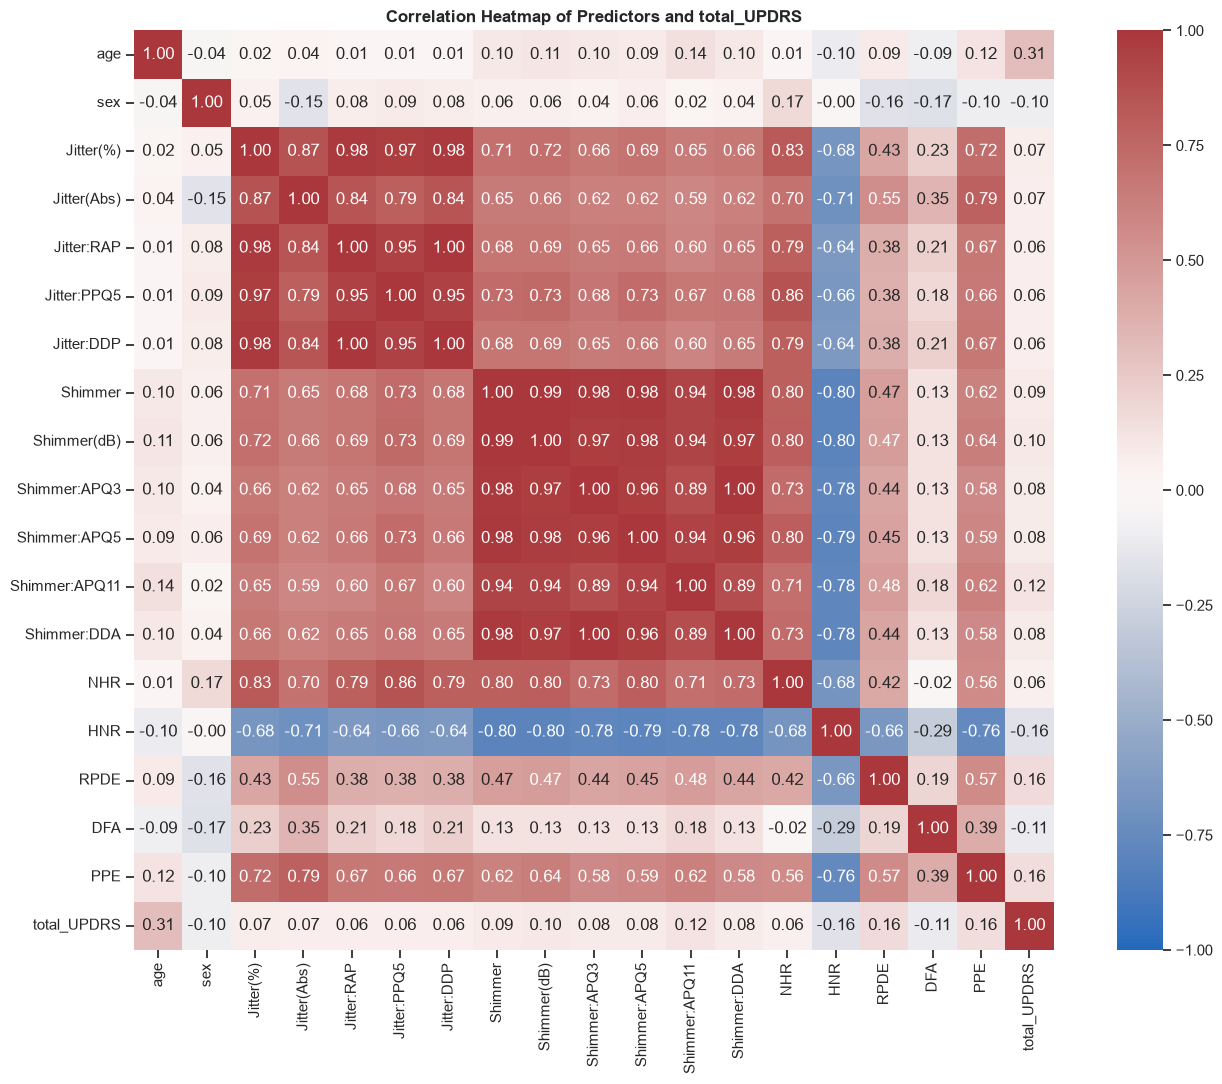

In [16]:
# Correlation heatmap among predictors and between each predictor and 'total_UPDRS'
corr_cols = X.columns.tolist() + ["total_UPDRS"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Heatmap of Predictors and total_UPDRS")
plt.tight_layout()
plt.show()

**Observations from the Correlation Heatmap:**

- **Linear Relationships with `total_UPDRS` (bottom row / rightmost column):**
  - Overall, individual linear correlations with `total_UPDRS` are weak to moderate, confirming the patterns observed in the scatterplots.
  - **`age` ($r = 0.31$):** Shows the strongest positive linear association with `total_UPDRS`, indicating that older patients tend to have higher UPDRS severity scores.
  - **Near-Zero Linear Correlations:** All `Jitter` measures, most `Shimmer` measures, and `NHR` have very weak linear correlations with `total_UPDRS`, suggesting that any predictive contribution from these variables is likely non-linear or dependent on interactions with other features.

  <br>

- **Severe Multicollinearity Among Predictors:**
  - **Jitter and Shimmer Clusters:** The Jitter variables are strongly correlated with one another, as are the Shimmer variables. This indicates substantial multicollinearity within each group of acoustic features, as several variables measure closely related aspects of voice signal variation.
  - **Cross-Cluster Acoustic Correlations:** There is also substantial positive correlation between the `Jitter` and `Shimmer` groups ($r = 0.59\text{ to }0.73$), as well as with `NHR` ($r = 0.70\text{ to }0.86$) and `PPE` ($r = 0.58\text{ to }0.79$).
  - **Inverse Relationship with `HNR`:** `HNR` (Harmonics-to-Noise Ratio) is strongly negatively correlated with `Shimmer` ($r = -0.78\text{ to }-0.80$), `Jitter` ($r = -0.64\text{ to }-0.71$), `NHR` ($r = -0.68$), and `PPE` ($r = -0.76$), which makes physical sense since higher harmonic clarity corresponds to lower vocal noise and perturbation.

<br>

**Implications for Modelling:**
1. **Need for Model Selection / Shrinkage:** The presence of exact collinearity ($r = 1.00$ between `Jitter:RAP`/`Jitter:DDP` and `Shimmer:APQ3`/`Shimmer:DDA`) and near-collinearity ($r > 0.95$) makes standard regression coefficients highly unstable with inflated variance. Applying model selection or shrinkage methods addresses this by penalising large parameter values in the objective function, which stabilises parameter estimation, reduces model variance, and diminishes the influence of redundant predictors (by shrinking their coefficients toward or all the way to zero).
2. **Justification for Non-Linear Models:** Because no single predictor has a correlation stronger than $r = 0.31$ with `total_UPDRS`, linear models alone may underfit the data. Tree-based ensembles are suitable to exploit non-linear relationships and higher-order feature interactions without being destabilised by multicollinearity.

---
#### **4. Model Development**

Based on the exploratory data analysis, several regression approaches are investigated to predict `total_UPDRS`. Linear Regression is first established as a baseline model, followed by Lasso regression to examine the effect of regularisation in the presence of highly correlated predictors. Random Forest is then explored as a nonlinear alternative to capture potentially complex relationships between acoustic features and symptom severity.

**4.1 Train-Test Split**

First, we separate the data into training (80%) and testing (20%) sets. Training sets are used to fit models, while testing sets are used for the final evaluation.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42  # For reproducibility
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (4700, 18)
Test set: (1175, 18)


**4.2 Standardised Evaluation Pipeline**

To ensure a fair and consistent comparison across all candidate models, a unified evaluation workflow is established using **5-fold cross-validation** and a reusable helper function (`evaluate_model`):

- **Shared Cross-Validation Splits (`KFold`):** A single 5-fold splitter (`shuffle=True, random_state=42`) is shared across all models so that hyperparameter tuning and validation performance are evaluated on the exact same data partitions.
- **Leakage-Free Preprocessing (`Pipeline`):** Each model is wrapped in a `Pipeline` alongside `StandardScaler()`. During cross-validation, scaling parameters (mean and standard deviation) are computed strictly on the 4 training folds and applied to the held-out validation fold, preventing data leakage.
- **Feature Standardisation:** Because the predictors are measured on vastly different scales (e.g., `Jitter(Abs)` on the order of $10^{-5}$ vs. `age` and `HNR` in the tens), the features are standardised to zero mean and unit variance ($\mu = 0, \sigma = 1$) using `StandardScaler` inside a `scikit-learn` `Pipeline`.
- **Consistent Metric Tracking:** For every model, the `evaluate_model` function records:
  - **Train RMSE & $R^2$:** In-sample goodness of fit on the full training set.
  - **CV RMSE & $R^2$:** Mean 5-fold cross-validation performance on held-out training folds, used to assess generalisation and diagnose potential overfitting before touching the test set.
  - **Test RMSE & $R^2$:** Final out-of-sample predictive performance on the held-out test set.

In [18]:
# Define a 5-fold CV splitter to use across all models
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store all model metrics
results = {}

# Define a reusable evaluation function
def evaluate_model(name, model, X_train, y_train, X_test, y_test, cv=cv, best_param=None):
    # Compute 5-fold CV metrics on the training set
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=("neg_root_mean_squared_error", "r2"),
        n_jobs=-1
    )
    cv_rmse = -np.mean(cv_scores["test_neg_root_mean_squared_error"])
    cv_r2 = np.mean(cv_scores["test_r2"])

    # Fit the model on the full training set and predict
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate train and test metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    # Save to the results dictionary
    results[name] = {
        "Best Parameter": best_param if best_param is not None else "N/A",
        "Train RMSE": train_rmse,
        "CV RMSE": cv_rmse,
        "Test RMSE": test_rmse,
        "Train R²": train_r2,
        "CV R²": cv_r2,
        "Test R²": test_r2
    }

    return model, y_train_pred, y_test_pred

**4.3 Linear Regression**

We start with **Ordinary Least Squares (OLS) Linear Regression** as a baseline model to evaluate how well a simple linear combination of the demographic and acoustic predictors can estimate Parkinson's disease severity (`total_UPDRS`). Before introducing regularisation penalties or ensemble architectures, it is essential to measure how much variance in `total_UPDRS` can be explained by simple linear relationships.

**How Linear Regression Works**:

Linear regression models the target variable $\hat{y}$ (`total_UPDRS`) as a weighted linear combination of the $p$ predictors ($x_1, x_2, \dots, x_p$) plus an intercept term $\beta_0$:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

To find the optimal coefficient values ($\beta_0, \beta_1, \dots, \beta_p$), the algorithm minimises the **Residual Sum of Squares (RSS)**—the sum of the squared differences between the observed target values $y_i$ and the model's predicted values $\hat{y}_i$ across all $n$ training observations:

$$\text{RSS} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

In [19]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

linear_model, lin_train_pred, lin_test_pred = evaluate_model(
    "Linear Regression", linear_model, X_train, y_train, X_test, y_test
)

**4.4 Shrinkage Methods: Lasso Regression**

From the correlation heatmap in Section 3.4, we observed severe multicollinearity within the `Jitter` and `Shimmer` feature groups (with several pairs reaching $r = 0.98\text{ to }1.00$). In standard Ordinary Least Squares (OLS) regression, high collinearity destabilises parameter estimation and inflates the variance of the regression coefficients. To address this, we apply **shrinkage**, specifically **Lasso Regression**, to constrain the coefficient estimates, reduce model variance, and improve out-of-sample generalisation.

**How Lasso Regression Works:**

Lasso regression modifies the standard OLS objective function by adding an $L_1$ regularisation penalty proportional to the sum of the absolute values of the regression coefficients ($\beta_j$):
$$\text{Objective} = \text{RSS} + \lambda \sum_{j=1}^{p} \vert{}\beta_j\vert{} = \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \lambda \sum_{j=1}^{p} \vert{}\beta_j\vert{}$$

- **The Shrinkage Penalty ($\sum_{j=1}^{p} \vert{}\beta_j\vert{}$):** The $L_1$ penalty forces the coefficients of redundant or uninformative predictors to become exactly zero when $\lambda$ is sufficiently large. This effectively performs simultaneous feature selection, leaving a sparser, more interpretable model containing only the most impactful predictors. Unlike Ridge regression ($L_2$), which merely shrinks weights towards zero, Lasso regression's identification of a subset of impactful predictors will be clinically valuable in biomedical contexts because it reduces diagnostic complexity and redundant computational overhead.
- **The Tuning Parameter ($\lambda$):** Controls the trade-off between fitting the training data (minimising $\text{RSS}$) and enforcing sparsity among the coefficients.

**Selecting $\lambda$ (`LassoCV`):** To determine the optimal regularisation strength $\lambda$ (`alpha` in `scikit-learn`), we evaluate 100 candidate values spaced logarithmically between $10^{-4}$ and $10^{4}$ (`np.logspace(-4, 4, 100)`) using our shared 5-fold cross-validation splitter, selecting the $\lambda$ that minimises the cross-validated Root Mean Squared Error (RMSE).

In [20]:
# Find the best lambda (alpha) using LassoCV
lasso_lamdas = np.logspace(-4, 4, 100)
lasso_tuner = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LassoCV(alphas=lasso_lamdas, cv=cv, max_iter=10000))
])
lasso_tuner.fit(X_train, y_train)
best_lasso_lamda = lasso_tuner.named_steps["regressor"].alpha_
print(f"Best Lasso lambda: {best_lasso_lamda:.4f}")

# Evaluate the final Lasso model with the selected lambda using our shared function
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=best_lasso_lamda, max_iter=10000))
])

lasso_model, lasso_train_pred, lasso_test_pred = evaluate_model(
    "Lasso Regression", lasso_model, X_train, y_train, X_test, y_test,
    best_param=f"λ = {best_lasso_lamda:.4f}"
)

Best Lasso lambda: 0.0183


**4.5 Non-Linear Ensemble Method: Random Forest Regression**

As observed in the exploratory scatterplots (Section 3.3) and correlation heatmap (Section 3.4), none of the individual predictors exhibit a strong linear relationship with `total_UPDRS` (the strongest being `age` at $r = 0.31$), and the acoustic features display complex, clustered patterns alongside heavy right-skewness and multicollinearity. While linear models (OLS, Lasso) are restricted to additive, straight-line relationships, **Random Forest Regression** is a flexible, non-parametric ensemble method capable of capturing non-linear relationships and high-order interactions among predictors. It would be suitable for capturing complex, multi-biomarker non-linear patterns inherent in neurological voice recordings.

**How Random Forest Regression Works:**

A Random Forest builds a large collection (ensemble) of $B$ decision trees and averages their individual predictions to produce a final estimate:

$$\hat{y} = \frac{1}{B} \sum_{b=1}^{B} T_b(\mathbf{x})$$

To prevent the individual decision trees from overfitting the training data and correlating with one another, Random Forest introduces two sources of randomness:
1. **Bootstrap Aggregation (Bagging):** Each tree $T_b$ is trained on an independent bootstrap sample (a random sample of size $n$ drawn with replacement from the training set).
2. **Random Feature Subspacing:** At each split node within a tree, rather than evaluating all $p$ predictors, the algorithm selects a random subset of $m$ predictors (`max_features`) and chooses the split that best reduces the variance (Mean Squared Error) of `total_UPDRS` within the resulting child nodes.
<br>

**Hyperparameter Tuning (`RandomizedSearchCV`):** We use our shared **5-fold cross-validation** splitter (`cv`) to tune the number of trees (`n_estimators`), maximum tree depth (`max_depth`), minimum samples required to split an internal node (`min_samples_split`), minimum samples per leaf (`min_samples_leaf`), and the fraction of features considered at each split (`max_features`) to balance model flexibility against overfitting.

**Feature Importance:** Random Forest has a built-in feature importance measurement, which measures how much each predictor reduces prediction error across all splits in the Random Forest, highlighting which variables contribute most to predicting `total_UPDRS`.

In [21]:
# Define the Random Forest pipeline
rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))
])

# Define a compact hyperparameter grid to tune via 5-fold CV
param_grid = {
    "regressor__n_estimators": [200, 500, 800],
    "regressor__max_depth": [None, 5, 10, 20, 30],
    "regressor__min_samples_split": [2, 5, 10, 20],
    "regressor__min_samples_leaf": [1, 2, 5, 10],
    "regressor__max_features": ["sqrt", 0.5, 0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipe,
    param_distributions=param_grid,
    n_iter=30,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)
best_rf_params = rf_search.best_params_
print("Best Random Forest Parameters:", best_rf_params)

# Evaluate the best model using the shared evaluate_model function
best_rf_model = rf_search.best_estimator_

param_str = (
    f"trees={best_rf_params['regressor__n_estimators']}, "
    f"depth={best_rf_params['regressor__max_depth']}, "
    f"split={best_rf_params['regressor__min_samples_split']}, "
    f"leaf={best_rf_params['regressor__min_samples_leaf']}, "
    f"feat={best_rf_params['regressor__max_features']}"
)

rf_model, rf_train_pred, rf_test_pred = evaluate_model(
    "Random Forest",
    best_rf_model,
    X_train,
    y_train,
    X_test,
    y_test,
    best_param=param_str
)

Best Random Forest Parameters: {'regressor__n_estimators': 500, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 1.0, 'regressor__max_depth': 30}


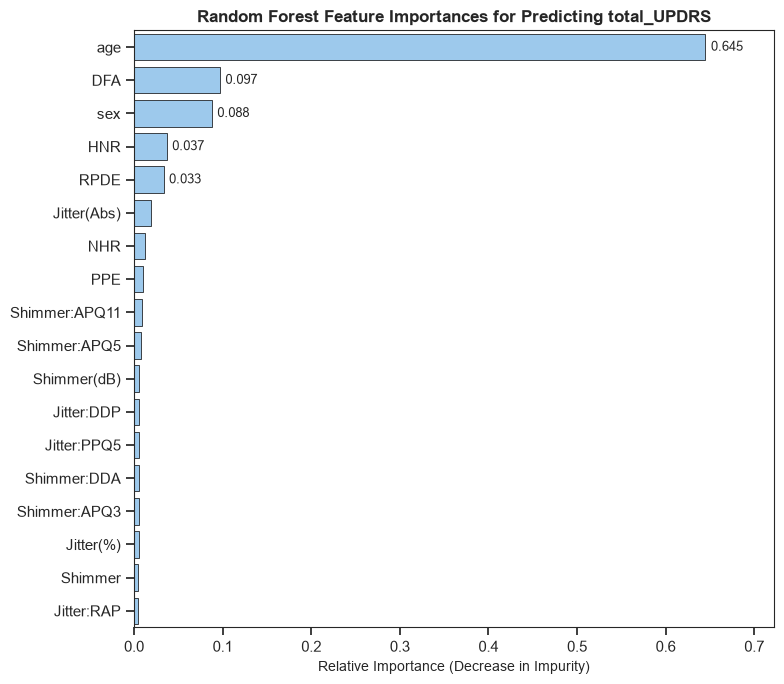

In [22]:
# Extract feature importances from the trained Random Forest
importances = rf_model.named_steps["regressor"].feature_importances_
feature_names = X_train.columns
feat_imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8,7))

# Barplot
sns.barplot(
    x=feat_imp_series.values,
    y=feat_imp_series.index,
    color=MAIN_COLOR,
    edgecolor="black",
    ax=ax
)
ax.grid(False)

# Label only the top 5 features (the first 5 bars from the top)
top_n = 5
labels = [
    f"{val:.3f}" if idx < top_n else ""
    for idx, val in enumerate(feat_imp_series.values)
]
ax.bar_label(ax.containers[0], labels=labels, padding=4, fontsize=9)
ax.set_xlim(0, feat_imp_series.max() * 1.12)

ax.set_title("Random Forest Feature Importances for Predicting total_UPDRS")
ax.set_xlabel("Relative Importance (Decrease in Impurity)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Observations from the Plot:**

- **Dominance of Demographic Predictors (`age` and `sex`):** `age` is overwhelmingly the most influential predictor, accounting for approximately **64%** of the total decrease in impurity (`~0.64`), while `sex` ranks third at roughly **9%** (`~0.088`). Because the dataset consists of repeated recordings from a fixed cohort of patients, the decision trees heavily utilise `age` and `sex` splits to isolate individual patients and their baseline `total_UPDRS` severity levels.
- **Key Non-Linear & Harmonic Acoustic Features (`DFA`, `HNR`, `RPDE`, `Jitter(Abs)`):** Among the voice biomarkers, `DFA` is the strongest contributor (`0.097`, second overall), followed by `HNR` (`0.037`) and `RPDE` (`~0.033`). This indicates that non-linear signal complexity and harmonic-to-noise ratio provide more unique predictive value than standard amplitude or frequency perturbation measures.
- **Diluted Importance Across Collinear `Jitter` and `Shimmer` Variants:** The remaining `Jitter` and `Shimmer` features (along with `NHR` and `PPE`) each have very small individual importance scores (`< 0.015`). Because these variables are highly correlated with one another ($r > 0.90$), their predictive contribution is split across multiple redundant features rather than concentrated in a single variable.

---
#### **5. Model Evaluation and Comparison**

To determine which regression approach best predicts Parkinson's disease severity (`total_UPDRS`), we compare all candidate models across the training set, 5-fold cross-validation (`CV`), and the held-out test set using two primary evaluation metrics: **Root Mean Squared Error (RMSE)** and the **Coefficient of Determination ($R^2$)**. We then inspect diagnostic plots (**Predicted vs. True Values** and **Residual Plots**) to evaluate how well the models perform across different severity levels.


**5.1 Evaluation Metrics**

1. **Root Mean Squared Error ($\text{RMSE}$):**
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
   - **Interpretation:** Measures the average magnitude of the prediction error in the **original units of `total_UPDRS`**. Because errors are squared before averaging, $\text{RMSE}$ penalises large prediction errors more heavily than smaller ones.
   - **Goal:** **Lower values indicate better predictive accuracy** ($\text{RMSE} = 0$ indicates a perfect fit). Comparing `Train RMSE`, `CV RMSE`, and `Test RMSE` also helps diagnose overfitting (when `Train RMSE` is substantially lower than `CV RMSE` and `Test RMSE`).

<br>

2. **Coefficient of Determination ($R^2$):**
   $$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2} = 1 - \frac{\text{RSS}}{\text{TSS}}$$
   - **Interpretation:** Represents the proportion of total variance in `total_UPDRS` explained by the model compared to a simple baseline model that always predicts the mean $\bar{y}$.
   - **Goal:** **Values closer to $1.0$ indicate a stronger fit**, while $R^2 = 0$ means the model performs no better than predicting the average `total_UPDRS` score.

In [23]:
# Display the comparison table across all models
results_df = pd.DataFrame(results).T
display(results_df)

,Best Parameter,Train RMSE,CV RMSE,Test RMSE,Train R²,CV R²,Test R²
Linear Regression,N/A,9.76643,9.808248,9.701222,0.173284,0.165758,0.150698
Lasso Regression,λ = 0.0183,9.770983,9.794163,9.696877,0.172513,0.168241,0.151459
Random Forest,"trees=500, depth=30, split=2, leaf=1, feat=1.0",1.132303,3.18938,2.969167,0.988888,0.911735,0.920443


**Performance Summary:**
- **Poor Linear Fit:** Both standard Linear Regression and Lasso Regression perform poorly on this dataset, achieving a high Test RMSE of $\approx9.70$ and a very low Test $R^2$ of only $0.151$. This indicates that linear models can only capture roughly 15% of the variance in total_UPDRS.
- **Lasso Shrinkage Effect:** The optimal shrinkage parameter selected via cross-validation was $\lambda = 0.0183$. Because this value is very small, Lasso's performance metrics and coefficients are virtually identical to standard OLS Linear Regression, meaning zeroing out coefficients did not significantly alter the linear fit or improve generalisation.
- **Random Forest Superiority:** In contrast to the linear models, Random Forest achieves exceptional predictive performance with a Test RMSE of $2.969$ and a Test $R^2$ of $0.920$, explaining 92% of the variance on unseen test data. While the training $R^2$ is very high ($0.989$, with a Train RMSE of $1.13$), the cross-validation RMSE ($3.189$) and Test RMSE ($2.969$) remain closely aligned and robust. This confirms that the model generalises extremely well to unseen data, successfully capturing the complex, non-linear interactions and feature thresholds present in the Parkinson's telemonitoring dataset that linear models failed to detect.

**5.2 Diagnostic Plots:**

Numeric metrics summarise performance into a single number, whereas diagnostic plots reveal *where* and *how* a model succeeds or fails across the range of `total_UPDRS`:

- **Predicted vs. True Value Plots:** Plot the model's predicted values ($\hat{y}_i$) on the y-axis against the actual observed `total_UPDRS` values ($y_i$) on the x-axis. For a perfect model, all points would fall directly along the $45^\circ$ diagonal identity line ($\hat{y} = y$). Deviations from this line reveal whether a model systematically underpredicts high severity scores or overpredicts low severity scores.
- **Residuals and Residual Plots:**
  - A **residual** ($e_i$) is the vertical difference between the actual observed target value and the model's predicted value:
    $$e_i = y_i - \hat{y}_i$$
    A positive residual ($e_i > 0$) means the model **underpredicted** the patient's severity, while a negative residual ($e_i < 0$) means the model **overpredicted** it.
  - A **Residual Plot** graphs the residuals ($e_i = y_i - \hat{y}_i$) on the y-axis against the predicted values ($\hat{y}_i$) on the x-axis. In a well-specified model, residuals should be **randomly and symmetrically scattered around the horizontal zero line ($e = 0$)** with constant vertical spread (homoscedasticity). Visible curves, slanted bands, or funnel shapes (heteroscedasticity) indicate uncaptured non-linear patterns or varying error across severity levels.

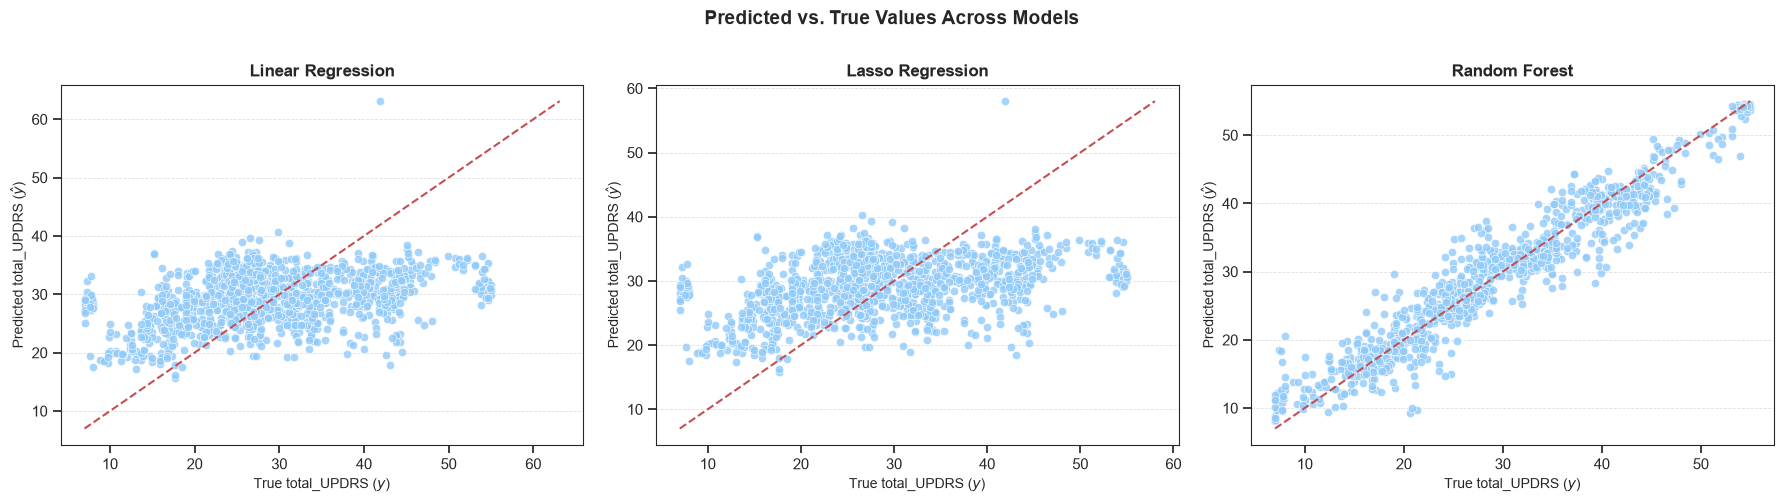

In [24]:
# Store test predictions for each model in a dictionary
model_preds = {
    "Linear Regression": lin_test_pred,
    "Lasso Regression": lasso_test_pred,
    "Random Forest": rf_test_pred
}

n_models = len(model_preds)

# Predicted vs. True Values
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))

for idx, (name, y_pred) in enumerate(model_preds.items()):
    ax = axes[idx]
    sns.scatterplot(
        x=y_test, y=y_pred,
        color=MAIN_COLOR, alpha=0.8, ax=ax
    )

    # 45-degree ideal reference line
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot(
        [min_val, max_val], [min_val, max_val],
        color=ACCENT_COLOR, linestyle="--", lw=1.5
    )

    ax.set_title(f"{name}")
    ax.set_xlabel(r"True total_UPDRS ($y$)")
    ax.set_ylabel(r"Predicted total_UPDRS ($\hat{y}$)")

plt.suptitle("Predicted vs. True Values Across Models", y=1)
plt.tight_layout()
plt.show()

**Observations from the plot:**
- **Linear & Lasso Regression:** Both linear models exhibit extreme compression in their predictions. Regardless of whether the true patient total_UPDRS score is low or high, both Linear and Lasso Regression restrict their predicted outputs to a very narrow band clustered around the mean ($\approx 25 \text{ to } 35$). They completely fail to capture the spread and extremes of the target variable, hugging a horizontal-like spread instead of aligning with the dashed 45-degree ideal reference line ($y = \hat{y}$).
- **Random Forest:** The Random Forest model displays a strong linear alignment along the 45-degree reference line. The predictions scale proportionally with the true values across the entire range of severity, proving that the ensemble effectively learns the underlying non-linear relationships and interactions between the predictors.
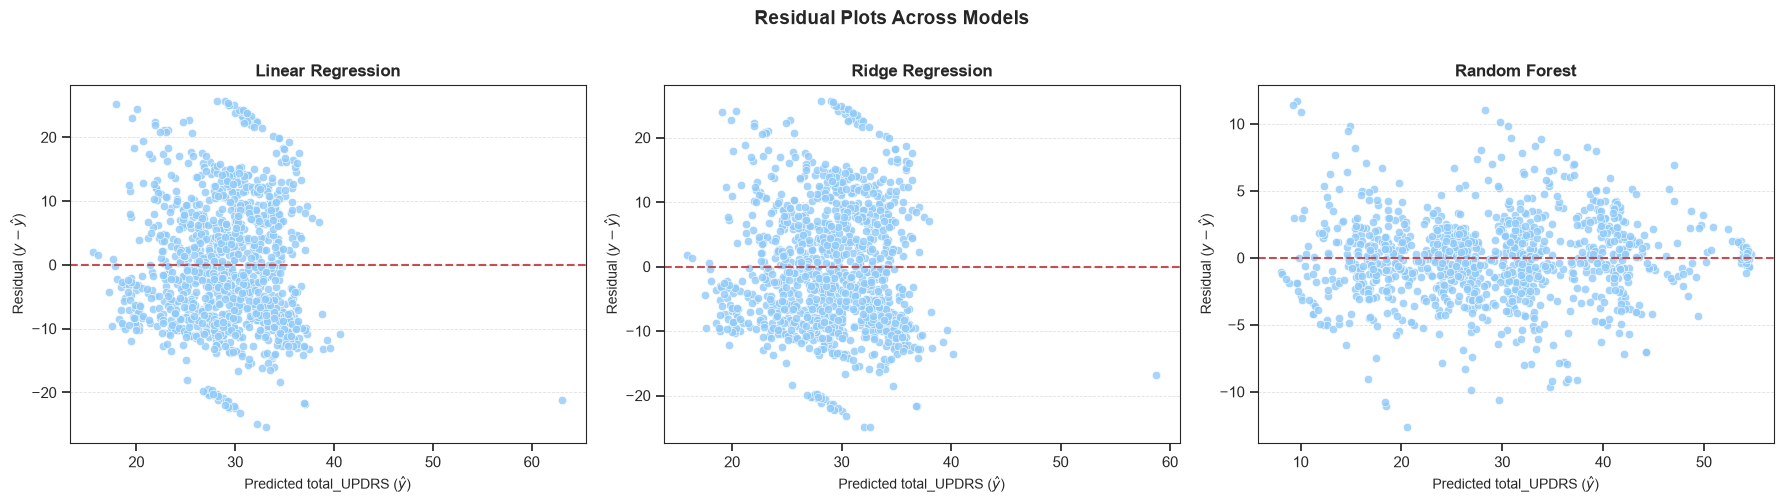

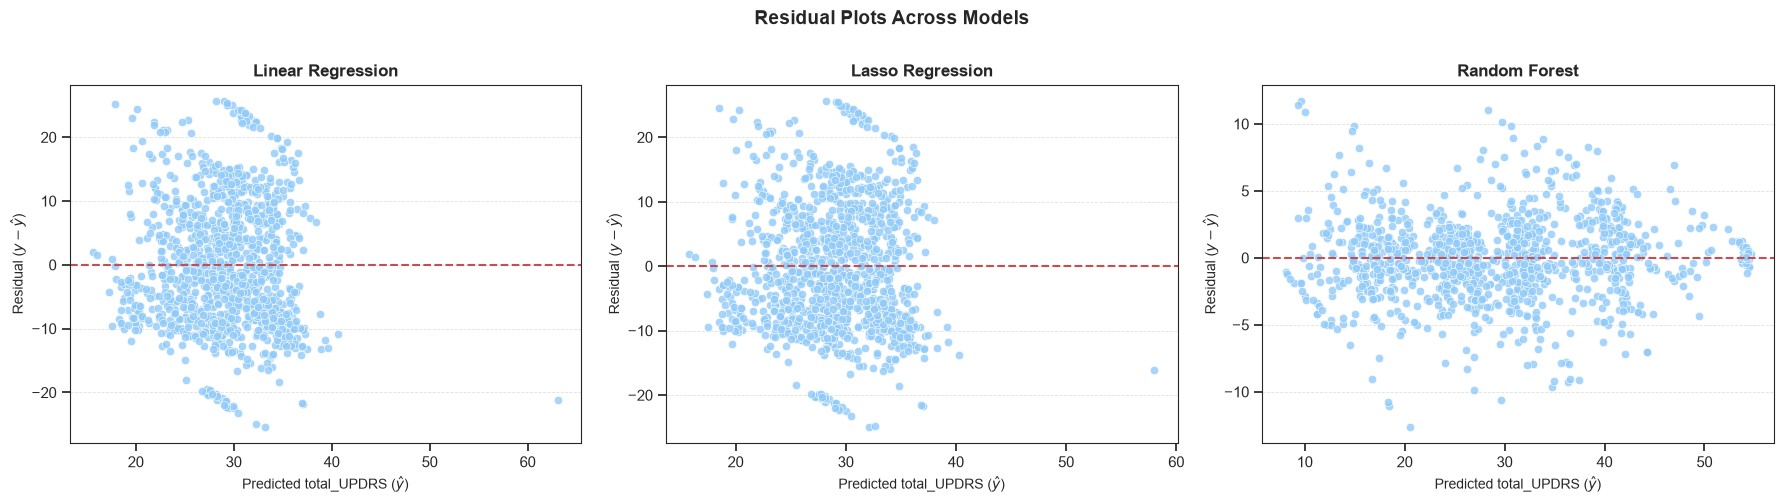

In [25]:
# Residual Plots (Residuals vs. Predicted Values)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))

for idx, (name, y_pred) in enumerate(model_preds.items()):
    ax = axes[idx]
    residuals = y_test - y_pred

    sns.scatterplot(
        x=y_pred, y=residuals,
        color=MAIN_COLOR, alpha=0.8, ax=ax
    )
    ax.axhline(
        0, color=ACCENT_COLOR, linestyle="--", lw=1.5
    )

    ax.set_title(f"{name}")
    ax.set_xlabel(r"Predicted total_UPDRS ($\hat{y}$)")
    ax.set_ylabel(r"Residual ($y - \hat{y}$)")

plt.suptitle("Residual Plots Across Models", y=1)
plt.tight_layout()
plt.show()

**Observations from the plot:**
- **Linear & Lasso Regression:** The residual plots for Linear and Lasso Regression reveal severe systematic bias and heteroscedasticity. The residuals form distinct, downward-sloping linear arcs/striations. This pattern indicates that the linear models systematically underpredict high scores and overpredict low scores, driven by their inability to model complex interactions. Furthermore, the spread of errors is large, with residuals stretching from $-25$ to $+25$.
- **Random Forest:** The Random Forest residual plot demonstrates a nearly ideal, random, homoscedastic scatter centred evenly around the zero error line ($\text{residual} = 0$). The errors are tightly bounded mostly between $-5$ and $+5$ with no discernible structural patterns or systematic bias across the predicted value range, confirming that the model's errors are purely random noise rather than uncaptured structural relationships.

**Discussion:**

The performance metrics demonstrate a substantial difference between the linear models and Random Forest. OLS Linear Regression achieved a test RMSE of 9.701 and a test $R^2$ of 0.151, indicating limited predictive performance. Lasso Regression produced very similar results, with a test RMSE of 9.697 and a test $R^2$ of 0.151. The marginal improvement suggests that Lasso's shrinkage did not meaningfully enhance predictive accuracy.

One possible explanation is the strong multicollinearity among the acoustic predictors identified during exploratory data analysis. Several jitter and shimmer features were highly correlated, suggesting that they contain overlapping information. Consequently, Lasso may eliminate some predictors while retaining correlated alternatives without substantially changing the overall predictions. Nevertheless, multicollinearity alone does not fully explain the limited predictive performance. Since Lasso remains a linear model, it may also be unable to capture complex nonlinear relationships between the predictors and total_UPDRS.

In contrast, Random Forest achieved a test RMSE of 2.969 and a test $R^2$ of 0.920, indicating substantially stronger predictive performance. This aligns directly with our exploratory data analysis (EDA), where individual acoustic and demographic predictors displayed little to no clear linear relationship with total_UPDRS, allowing tree-based ensemble methods to capture the underlying non-linear interactions and threshold dynamics that linear models failed to detect.

However, while Random Forest demonstrated outstanding test set performance, critical inspection of feature importances reveals an important methodological limitation inherent in telemonitoring datasets:

1. `age` as a Surrogate Patient Identifier:
   * Random Forest assigned approximately 64.5% of its total importance to `age` alone according to the feature importance.
   * Because the dataset comprises 5,875 recordings derived from only 42 unique subjects, each participant contributed roughly 140 recordings where demographic features (`age`, `sex`) remained invariant.
   * Consequently, within this small cohort of 42 individuals, a specific `age` (e.g., 72 years old) effectively serves as a proxy for `subject#`.

<br>

2. Clustered Train-Test Split Leakage:
   * Because standard random record splitting (`train_test_split`) was performed at the recording level rather than the patient level, voice recordings from the same individual exist in both the training and test sets.
   * The ensemble's deep decision trees (`max_depth=30`) might greedily split on `age` at root nodes, effectively memorising each patient's baseline severity rather than purely learning the acoustic biomarkers of voice degradation.
   * This also explains the large gap between linear models and Random Forest as linear models are constrained to a single global slope and cannot isolate patient clusters, whereas deep decision trees easily partition patients into discrete demographic leaves.

<br>

3. Recommendations for Future Work:
   * To evaluate true clinical utility on unseen patients, future model iterations should implement `GroupKFold` cross-validation grouped strictly by `subject#`. This ensures that test folds contain only unseen patients, forcing the algorithm to rely exclusively on vocal biomarkers (Jitter, Shimmer, HNR, RPDE) rather than demographic memorisation.

Overall, the results suggest that Random Forest was better suited to this prediction task than the two linear models, while Lasso's limited improvement indicates that regularisation and feature selection alone were insufficient to achieve comparable predictive accuracy.

---
#### **6. Conclusion**

This project aimed to predict Parkinson’s disease severity, measured by `total_UPDRS`, using demographic and acoustic features from the Oxford Parkinson’s Disease Telemonitoring Dataset. Exploratory data analysis revealed that most individual predictors had relatively weak linear correlations with the target, while several acoustic features exhibited strong correlations with one another. These observations motivated the comparison of linear and nonlinear regression models.

Among the models evaluated, the **Random Forest Regression model** achieved the best overall predictive performance, with a **test RMSE of 2.97 and a test $R^2$ of 0.92**. In comparison, Linear Regression and Lasso Regression achieved test RMSE values of approximately 9.7, with test $R^2$ values of approximately 0.15 for both models. These results suggest that Random Forest was better able to capture complex relationships between the predictors and `total_UPDRS` than the linear models. Residual analysis also showed that the linear models had a wider spread of residuals and more visible patterns, whereas Random Forest residuals were more concentrated around zero, indicating smaller prediction errors overall.

Several limitations should be considered when interpreting these results. The dataset contains repeated recordings from the same participants, and the random row-level train/test split may place recordings from the same participant in both sets. Consequently, the reported performance may not fully reflect the model’s ability to predict severity for previously unseen individuals. In addition, the strong correlations among some acoustic predictors may affect the interpretability of linear-model coefficients and the distribution of feature importance among correlated predictors.

Future work could evaluate the models using participant-wise cross-validation or a participant-wise test split to assess generalisation to unseen individuals. Further investigation of feature selection, alternative modelling approaches, and hyperparameter tuning could also help improve predictive performance. Overall, this project demonstrates the potential of regression models to estimate Parkinson’s disease severity from demographic and acoustic measurements, while highlighting the importance of appropriate validation and careful interpretation of predictive results.

_Note: See `README.md` for reflection on FAIR Principles and License._